In [1]:
# SECTION 13: Preprocess log messages with TF-IDF

import re

import string

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

import nltk

from nltk.corpus import stopwords

from nltk.tokenize import word_tokenize

from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer

# NLTK resources
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")

# Load cleaned logs and show full message text
logs = pd.read_csv("data/clean_logs.csv", parse_dates=["timestamp"])

pd.set_option("display.max_colwidth", None)

print("Sample raw messages :")
print(logs["log_message"].sample(8, random_state=42).to_string())

# Stopwords, keeping negations that change meaning
stop_words = set(stopwords.words("english")) - {"not", "no"}

lemmatizer = WordNetLemmatizer()

# Remove the level prefix, IDs, numbers, and punctuation, then lemmatize
def clean_log(text):
    text = re.sub(r"^(INFO|WARNING|ERROR):\s*", "", text)
    text = text.lower()
    text = re.sub(r"[a-z_]*\d+[a-z0-9_]*", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2]
    return " ".join(tokens)

logs["clean_message"] = logs["log_message"].apply(clean_log)

# Distinct message patterns after cleaning
print()
print("Distinct cleaned messages :", logs["clean_message"].nunique())
print()
print(logs.groupby(["log_level", "clean_message"]).size().sort_values(ascending=False).to_string())

# TF-IDF on single words and word pairs
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)

tfidf_matrix = tfidf.fit_transform(logs["clean_message"])

print()
print("TF-IDF matrix shape :", tfidf_matrix.shape)

# Highest average TF-IDF terms
mean_scores = pd.Series(np.asarray(tfidf_matrix.mean(axis=0)).ravel(), index=tfidf.get_feature_names_out())

print()
print("Top 15 TF-IDF terms :")
print(mean_scores.sort_values(ascending=False).head(15).round(4))

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/wyatthockmeyer1/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/wyatthockmeyer1/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/wyatthockmeyer1/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/wyatthockmeyer1/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/wyatthockmeyer1/nltk_data...


Sample raw messages :
676                          ERROR: API rate limit exceeded for endpoint /api/transactions
4711    ERROR: RTGS transaction failed. Transaction ID: TXN747. Reason: Insufficient funds
3455    ERROR: RTGS transaction failed. Transaction ID: TXN180. Reason: Insufficient funds
1558                                                INFO: Cache refresh completed in 829ms
2634    ERROR: RTGS transaction failed. Transaction ID: TXN721. Reason: Insufficient funds
1752                       WARNING: Duplicate transaction detected. Transaction ID: TXN384
2086                                         ERROR: Disk I/O bottleneck detected on srv-13
4836                                  INFO: Transaction processed successfully. ID: TXN753

Distinct cleaned messages : 17

log_level  clean_message                                               
WARNING    duplicate transaction detected transaction                      337
INFO       cache refresh completed                                

k = 2 | silhouette : 0.1428
k = 3 | silhouette : 0.2026
k = 4 | silhouette : 0.2717
k = 5 | silhouette : 0.3335
k = 6 | silhouette : 0.3897
k = 7 | silhouette : 0.4435
k = 8 | silhouette : 0.5042
k = 9 | silhouette : 0.5626
k = 10 | silhouette : 0.6218
k = 11 | silhouette : 0.6781
k = 12 | silhouette : 0.7366

Best k : 12

===== Cluster 0 | 278 logs =====
log_level  clean_message                   
WARNING    container srv restarting due oom    278

===== Cluster 1 | 835 logs =====
log_level  clean_message                                               
ERROR      imp transaction failed transaction reason invalid account       264
           neft transaction failed transaction reason gateway timeout      292
           rtgs transaction failed transaction reason insufficient fund    279

===== Cluster 2 | 600 logs =====
log_level  clean_message                                   
ERROR      high cpu utilization detected server srv current    304
WARNING    memory usage approaching thresho

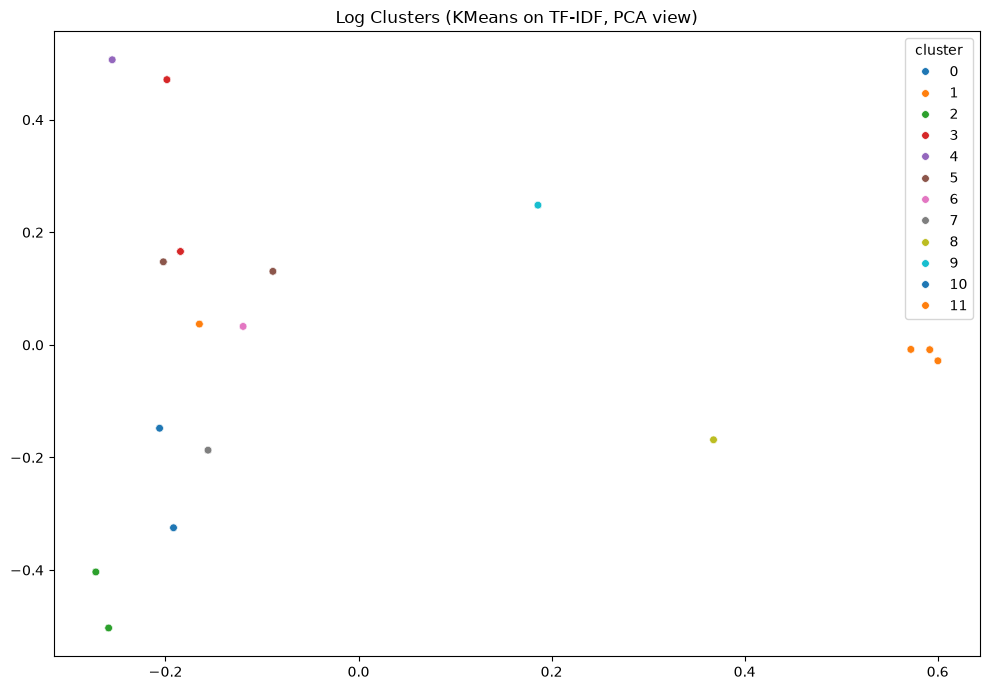

In [2]:
# SECTION 14: Cluster log messages with KMeans

from sklearn.cluster import KMeans

from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA

# Silhouette score for a range of cluster counts
scores = {}
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(tfidf_matrix)
    scores[k] = silhouette_score(tfidf_matrix, labels)
    print("k =", k, "| silhouette :", round(scores[k], 4))

# Choose the k with the highest silhouette score
best_k = max(scores, key=scores.get)

print()
print("Best k :", best_k)

# Fit the final model and label every log
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)

logs["cluster"] = kmeans.fit_predict(tfidf_matrix)

# Which message templates landed in each cluster
print()
for c in sorted(logs["cluster"].unique()):
    members = logs[logs["cluster"] == c]
    print("===== Cluster", c, "|", len(members), "logs =====")
    print(members.groupby(["log_level", "clean_message"]).size().to_string())
    print()

# Top terms that define each cluster
terms = tfidf.get_feature_names_out()

for c in range(best_k):
    top_idx = kmeans.cluster_centers_[c].argsort()[::-1][:6]
    print("Cluster", c, "top terms :", [terms[i] for i in top_idx])

# 2D view of the clusters
coords = PCA(n_components=2, random_state=42).fit_transform(tfidf_matrix.toarray())

plt.figure(figsize=(10, 7))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=logs["cluster"], palette="tab10", s=30)
plt.title("Log Clusters (KMeans on TF-IDF, PCA view)")
plt.tight_layout()
plt.show()

log_level          ERROR  INFO  WARNING   All
issue_category                               
Business KPI        1121     0      615  1736
Infrastructure      1442     0      574  2016
Normal Operations      0  1239        0  1239
All                 2563  1239     1189  4991

issue_category  cluster_name                               
Business KPI    Payment channel failures (NEFT, IMPS, RTGS)    835
Infrastructure  CPU and memory pressure                        600
Business KPI    Duplicate transactions                         337
Infrastructure  Network timeouts                               294
Business KPI    Customer authentication                        286
Infrastructure  Disk I/O bottleneck                            284
                Database connection pool                       283
Business KPI    Payment gateway SLA breach                     278
Infrastructure  Container OOM restarts                         278
                API rate limiting                           

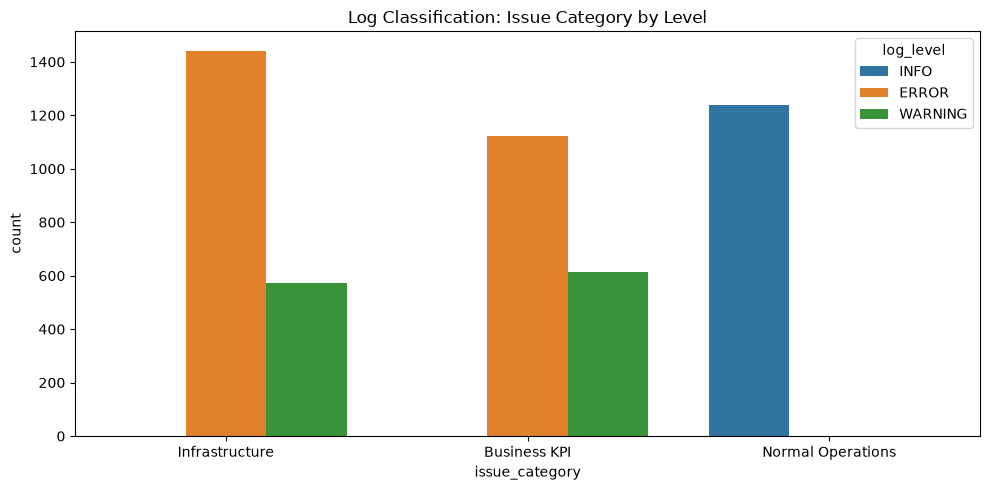

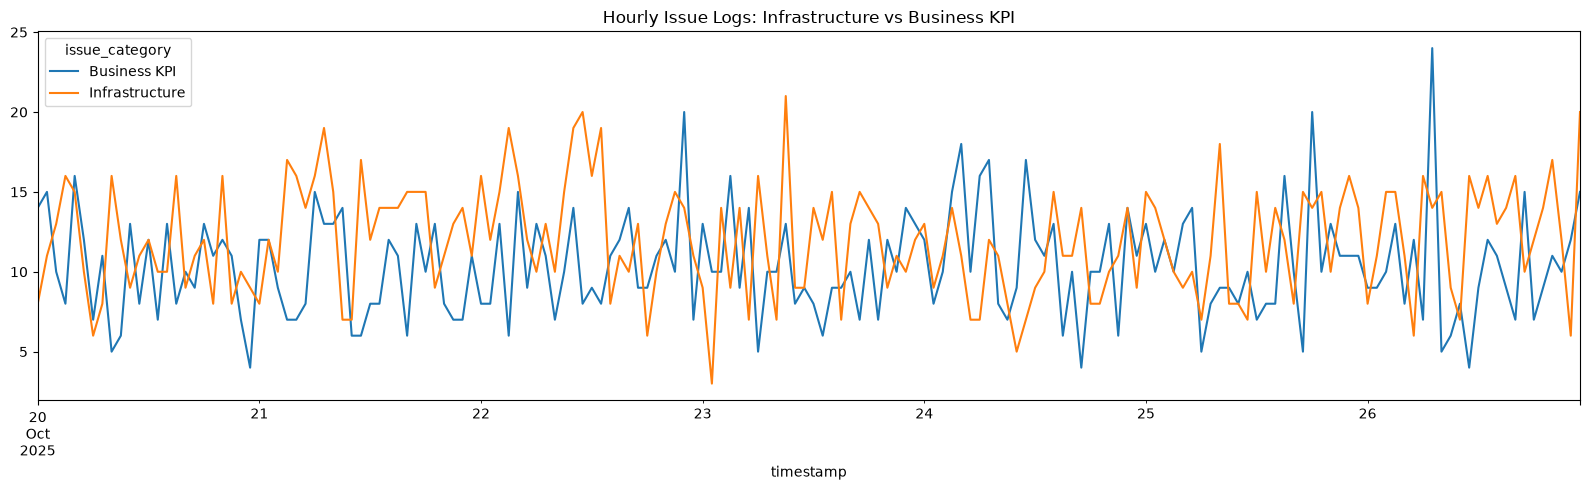


Saved clustered_logs.csv, log_vectorizer, log_kmeans, and log_cluster_map


In [3]:
# SECTION 14B: Label clusters as infrastructure or business KPI issues

import os

import joblib

# Plain-language name for each cluster, from Section 14 output
cluster_name = {0: "Container OOM restarts", 1: "Payment channel failures (NEFT, IMPS, RTGS)", 2: "CPU and memory pressure", 3: "Database connection pool", 4: "Cache operations", 5: "Customer authentication", 6: "Payment gateway SLA breach", 7: "Network timeouts", 8: "Duplicate transactions", 9: "Successful transactions", 10: "Disk I/O bottleneck", 11: "API rate limiting"}

# Issue type for each cluster
cluster_category = {0: "Infrastructure", 1: "Business KPI", 2: "Infrastructure", 3: "Infrastructure", 4: "Infrastructure", 5: "Business KPI", 6: "Business KPI", 7: "Infrastructure", 8: "Business KPI", 9: "Business KPI", 10: "Infrastructure", 11: "Infrastructure"}

logs["cluster_name"] = logs["cluster"].map(cluster_name)

logs["issue_category"] = logs["cluster"].map(cluster_category)

# INFO logs are normal operations, not issues
logs.loc[logs["log_level"] == "INFO", "issue_category"] = "Normal Operations"

# Counts by category and level
print(pd.crosstab(logs["issue_category"], logs["log_level"], margins=True))

print()
print(logs[logs["issue_category"] != "Normal Operations"].groupby(["issue_category", "cluster_name"]).size().sort_values(ascending=False).to_string())

# Issue volume by category and level
plt.figure(figsize=(10, 5))
sns.countplot(data=logs, x="issue_category", hue="log_level", order=["Infrastructure", "Business KPI", "Normal Operations"])
plt.title("Log Classification: Issue Category by Level")
plt.tight_layout()
plt.show()

# Hourly issue trend for the two issue types
hourly_issues = logs[logs["issue_category"] != "Normal Operations"].set_index("timestamp").groupby("issue_category").resample("h").size().unstack(0)

hourly_issues.plot(figsize=(16, 5), title="Hourly Issue Logs: Infrastructure vs Business KPI")
plt.tight_layout()
plt.show()

# Save labeled logs and the log models for the API and dashboard
logs.to_csv("data/clustered_logs.csv", index=False)

os.makedirs("models", exist_ok=True)

joblib.dump(tfidf, "models/log_vectorizer.joblib")

joblib.dump(kmeans, "models/log_kmeans.joblib")

joblib.dump({"cluster_name": cluster_name, "cluster_category": cluster_category}, "models/log_cluster_map.joblib")

print()
print("Saved clustered_logs.csv, log_vectorizer, log_kmeans, and log_cluster_map")

In [4]:
# SECTION 15: Build the knowledge base (runbooks and historical incident records)

# Scored infrastructure data (incident and anomaly columns) and clustered logs
infra = pd.read_csv("data/scored_infrastructure.csv", parse_dates=["timestamp"])

logs = pd.read_csv("data/clustered_logs.csv", parse_dates=["timestamp"])

# Folders for the two document types
os.makedirs("kb/runbooks", exist_ok=True)

os.makedirs("kb/incidents", exist_ok=True)

# Runbook documentation, one per issue type
runbooks = {
"auth_drop_error_spike": """RUNBOOK: Authentication Failure with Application Error Spike
Issue category: Business KPI (customer impact) with an application-layer cause
Signature: auth_success_rate falls below 98 percent (normal band 98.5 to 99.5) in the same minute application errors reach 6 or more per minute.
History: 175 minutes over 7 days, spread across all hours and days. Not linked to CPU, memory, or transaction volume.
Business impact: Customers cannot log in or authorize payments. Failed logins drive abandoned transactions and contact-center volume.
Likely root causes: Identity provider or token service faults, a defect in a recent application release, or a failing dependency in the authentication path. Capacity is not the cause.
Diagnostic steps: 1. Confirm customer authentication failed logs in the same window. 2. Check API rate limiting and network timeout logs for a shared dependency. 3. Check deployments in the prior 24 hours. 4. Check identity provider health.
Remediation: Fail over to the secondary authentication node, roll back the most recent release if it lines up with the first spike, and clear the token cache.
Escalation: Page the on-call application owner at once. The incident classifier flags these minutes automatically.""",

"peak_load_latency": """RUNBOOK: Peak-Load Processing Latency
Issue category: Infrastructure
Signature: From 09:00 to 17:59, weekday CPU runs 65 to 77 percent and average processing time rises to about 400 ms, compared with a 100 ms off-peak floor. Weekends peak near 50 percent CPU and 200 ms.
Evidence: Processing time correlates 0.99 with CPU, 0.97 with memory, and 0.89 with transaction volume. CPU never passed 77.5 percent, so the system has not saturated.
Business impact: Slower payments during business hours, when customer volume is highest.
Likely root causes: Predictable daily demand.
Diagnostic steps: 1. Compare current CPU and latency with the forecast. 2. Check DB connection pool usage and network throughput for the same minutes.
Remediation: Use the CPU and latency forecasts to scale capacity before 09:00 and release it after 18:00. Alert if CPU forecast exceeds 80 percent.
Escalation: Capacity planning team if peak latency exceeds 450 ms for 15 minutes.""",

"payment_channel_failures": """RUNBOOK: Payment Channel Failures (NEFT, IMPS, RTGS)
Issue category: Business KPI
Log signature: NEFT transaction failed with gateway timeout. IMPS transaction failed with invalid account. RTGS transaction failed with insufficient funds.
Business impact: Failed customer payments and lower channel success rates. RTGS failures involve high-value transfers.
Likely root causes: Gateway timeouts point to the NEFT clearing interface or its network path. Invalid account points to beneficiary validation data or customer input. Insufficient funds is a customer-side decline, not a system fault.
Diagnostic steps: 1. Split failures by channel and reason. 2. Compare with channel success rates in the same window (normal: NEFT 96 to 100, IMPS 98 to 100, RTGS 99 to 100 percent). 3. For gateway timeouts, check network timeout and gateway SLA logs.
Remediation: Route gateway timeouts to the standby gateway. Correct beneficiary validation data. Exclude insufficient-funds declines from system failure alerts.
Escalation: Payments operations if a channel falls below its normal band for 5 minutes.""",

"cpu_memory_pressure": """RUNBOOK: CPU and Memory Pressure
Issue category: Infrastructure
Log signature: High CPU utilization detected on server. Memory usage approaching threshold.
Business impact: Higher processing time and risk of container restarts.
Likely root causes: Peak-hour demand, runaway batch jobs, or memory leaks after a release.
Diagnostic steps: 1. Check whether the alert falls inside 09:00 to 17:59. 2. Compare with the CPU and memory forecasts. 3. Look for container OOM restart logs on the same server.
Remediation: Scale out the affected service, move batch jobs out of peak hours, and restart leaking processes during a low-volume window.
Escalation: Platform engineering if memory stays above 65 percent outside peak hours.""",

"database_connection_pool": """RUNBOOK: Database Connection Pool Exhausted
Issue category: Infrastructure
Log signature: Database connection pool exhausted.
Business impact: Transactions wait for a connection or fail, which raises processing time.
Likely root causes: Long-running queries, connection leaks, or a pool sized below peak demand.
Diagnostic steps: 1. Check db_connection_pool_usage for the window. 2. Identify long-running queries. 3. Check whether a database backup overlapped the window.
Remediation: Kill blocking queries, raise the pool size for peak hours, and schedule backups outside 09:00 to 17:59.
Escalation: Database administrator on repeat events within one hour.""",

"network_timeouts": """RUNBOOK: Critical Network Timeouts
Issue category: Infrastructure
Log signature: Critical network timeout on server with latency value.
Business impact: Payment gateway calls and authentication calls time out, which shows up as NEFT gateway timeouts and SLA breaches.
Likely root causes: Packet loss, saturated links, DNS issues, or a failing network device.
Diagnostic steps: 1. Check network_throughput_mbps in the window. 2. Check for matching gateway SLA and NEFT timeout logs. 3. Trace the route to the affected server.
Remediation: Fail over to the secondary network path and open a ticket with the network provider.
Escalation: Network operations if timeouts repeat on the same server within 15 minutes.""",

"disk_io_bottleneck": """RUNBOOK: Disk I/O Bottleneck
Issue category: Infrastructure
Log signature: Disk I/O bottleneck detected on server.
Business impact: Slower database writes and logging, which raises processing time.
Likely root causes: Backup jobs, log volume growth, or a degraded disk.
Diagnostic steps: 1. Check whether a backup or batch job was running. 2. Check disk health on the named server.
Remediation: Move heavy I/O jobs off peak hours, rotate logs, and replace degraded disks.
Escalation: Infrastructure team if the same server repeats within one day.""",

"container_oom_restarts": """RUNBOOK: Container Restarts Due to Out of Memory
Issue category: Infrastructure
Log signature: Container restarting due to OOM.
Business impact: In-flight transactions on that container fail or retry.
Likely root causes: Memory limits set too low, memory leaks, or traffic spikes.
Diagnostic steps: 1. Check memory_usage before the restart. 2. Check the container memory limit. 3. Check for a recent release.
Remediation: Raise the memory limit, fix the leak, and add a replica for peak hours.
Escalation: Application owner after 3 restarts of the same container in one hour.""",

"api_rate_limiting": """RUNBOOK: API Rate Limit Exceeded
Issue category: Infrastructure
Log signature: API rate limit exceeded for endpoint /api/transactions.
Business impact: Partner and channel requests are rejected and must retry.
Likely root causes: A partner retry storm, a misconfigured client, or limits set below peak demand.
Diagnostic steps: 1. Identify the calling client. 2. Compare request volume with transaction_volume_per_hour.
Remediation: Throttle the offending client, apply backoff on retries, and review limits for peak hours.
Escalation: API platform owner if legitimate traffic is being rejected.""",

"customer_authentication": """RUNBOOK: Customer Authentication Failures (log level)
Issue category: Business KPI
Log signature: Customer authentication failed for user.
Business impact: Customers locked out of digital channels.
Likely root causes: Wrong credentials (expected), identity provider faults, or credential-stuffing attacks.
Diagnostic steps: 1. Compare failure volume with auth_success_rate. 2. Look for many failures from few sources. 3. Check whether the minute is a flagged incident.
Remediation: Apply the Authentication Failure with Application Error Spike runbook for flagged incidents. Block abusive sources for attack patterns.
Escalation: Security operations for suspected credential stuffing.""",

"payment_gateway_sla": """RUNBOOK: Payment Gateway Response Time Exceeded SLA
Issue category: Business KPI
Log signature: Payment gateway response time exceeded SLA.
Business impact: Slow payment confirmations and possible timeouts.
Likely root causes: Gateway vendor degradation or network latency to the gateway.
Diagnostic steps: 1. Check network timeout logs in the same window. 2. Check the vendor status page. 3. Compare with NEFT gateway timeout failures.
Remediation: Route traffic to the standby gateway and notify the vendor.
Escalation: Vendor management after 3 SLA breaches in one hour.""",

"duplicate_transactions": """RUNBOOK: Duplicate Transactions Detected
Issue category: Business KPI
Log signature: Duplicate transaction detected.
Business impact: Risk of double charges and reconciliation errors.
Likely root causes: Client retries after timeouts, or missing idempotency checks.
Diagnostic steps: 1. Check for network timeouts or gateway delays just before the duplicates. 2. Confirm whether the duplicate was blocked or posted.
Remediation: Reverse any posted duplicates and enforce idempotency keys on retries.
Escalation: Reconciliation team for any posted duplicate."""
}

# Write each runbook to its own file
for name, text in runbooks.items():
    file = open("kb/runbooks/" + name + ".txt", "w")
    file.write(text)
    file.close()

# Group incident minutes into episodes (gaps over 5 minutes start a new one)
inc = infra[infra["incident"] == 1].copy()

inc["gap"] = inc["timestamp"].diff().dt.total_seconds() / 60

inc["episode"] = (inc["gap"].isna() | (inc["gap"] > 5)).cumsum()

# Issue logs only, for matching to each episode
issue_logs = logs[logs["issue_category"] != "Normal Operations"]

# Write one historical incident record per episode
for ep, rows in inc.groupby("episode"):
    start = rows["timestamp"].min()
    end = rows["timestamp"].max()
    hour = start.hour
    if hour >= 9 and hour <= 17:
        period = "Peak hours (09:00 to 17:59)"
    else:
        period = "Off-peak hours"
    window = issue_logs[(issue_logs["timestamp"] >= start - pd.Timedelta(minutes=5)) & (issue_logs["timestamp"] <= end + pd.Timedelta(minutes=5))]
    log_summary = window["cluster_name"].value_counts().head(3)
    log_text = ""
    for cname, count in log_summary.items():
        log_text = log_text + cname + " (" + str(count) + "), "
    if log_text == "":
        log_text = "No issue logs within 5 minutes"

    record = "HISTORICAL INCIDENT INC-" + str(ep).zfill(3) + "\n"
    record = record + "Type: Authentication failure with application error spike\n"
    record = record + "Start: " + str(start) + "\n"
    record = record + "End: " + str(end) + "\n"
    record = record + "Incident minutes: " + str(len(rows)) + "\n"
    record = record + "Day type: " + rows["day_type"].iloc[0] + " | Period: " + period + "\n"
    record = record + "Lowest auth success rate: " + str(round(rows["auth_success_rate"].min(), 2)) + " percent\n"
    record = record + "Highest application errors per minute: " + str(rows["application_error_rate"].max()) + "\n"
    record = record + "Average CPU: " + str(round(rows["cpu_utilization"].mean(), 1)) + " percent | Average processing time: " + str(round(rows["avg_transaction_processing_time_ms"].mean(), 1)) + " ms\n"
    record = record + "Average success rates: NEFT " + str(round(rows["neft_success_rate"].mean(), 2)) + ", IMPS " + str(round(rows["imps_success_rate"].mean(), 2)) + ", RTGS " + str(round(rows["rtgs_success_rate"].mean(), 2)) + "\n"
    record = record + "IsolationForest flagged minutes: " + str(rows["anomaly"].sum()) + " of " + str(len(rows)) + "\n"
    record = record + "Issue logs within 5 minutes: " + log_text + "\n"
    record = record + "Applicable runbook: Authentication Failure with Application Error Spike\n"

    file = open("kb/incidents/INC-" + str(ep).zfill(3) + ".txt", "w")
    file.write(record)
    file.close()

# Summary record for load anomalies found only by IsolationForest
load_only = infra[(infra["anomaly"] == 1) & (infra["incident"] == 0)]

summary = "HISTORICAL PATTERN: Load Anomalies Detected by IsolationForest Only\n"
summary = summary + "Minutes flagged: " + str(len(load_only)) + "\n"
summary = summary + "Share in peak hours: " + str(round((load_only["hour"].between(9, 17)).mean() * 100, 1)) + " percent\n"
summary = summary + "Average CPU: " + str(round(load_only["cpu_utilization"].mean(), 1)) + " percent | Average processing time: " + str(round(load_only["avg_transaction_processing_time_ms"].mean(), 1)) + " ms\n"
summary = summary + "Includes the single service uptime dip: " + str(int(load_only["service_uptime"].min() < 100)) + "\n"
summary = summary + "Applicable runbook: Peak-Load Processing Latency\n"

file = open("kb/incidents/load_anomalies_summary.txt", "w")
file.write(summary)
file.close()

# Confirm what was written and show one record
print("Runbooks written :", len(os.listdir("kb/runbooks")))
print("Incident records written :", len(os.listdir("kb/incidents")))
print()

file = open("kb/incidents/INC-001.txt", "r")
print(file.read())
file.close()

print(summary)

Runbooks written : 12
Incident records written : 164

HISTORICAL INCIDENT INC-001
Type: Authentication failure with application error spike
Start: 2025-10-20 00:35:00
End: 2025-10-20 00:35:00
Incident minutes: 1
Day type: Weekday | Period: Off-peak hours
Lowest auth success rate: 96.65 percent
Highest application errors per minute: 6
Average CPU: 42.6 percent | Average processing time: 145.8 ms
Average success rates: NEFT 96.11, IMPS 98.75, RTGS 99.81
IsolationForest flagged minutes: 1 of 1
Issue logs within 5 minutes: Payment channel failures (NEFT, IMPS, RTGS) (1), 
Applicable runbook: Authentication Failure with Application Error Spike

HISTORICAL PATTERN: Load Anomalies Detected by IsolationForest Only
Minutes flagged: 55
Share in peak hours: 100.0 percent
Average CPU: 72.2 percent | Average processing time: 421.1 ms
Includes the single service uptime dip: 0
Applicable runbook: Peak-Load Processing Latency



In [5]:
# SECTION 16: RAG pipeline over the knowledge base (Chroma + gpt-5-mini)

import shutil

from dotenv import load_dotenv

from langchain_chroma import Chroma

from langchain_text_splitters import RecursiveCharacterTextSplitter

from langchain_openai import ChatOpenAI, OpenAIEmbeddings

from langchain.chains import create_retrieval_chain

from langchain.chains.combine_documents import create_stuff_documents_chain

from langchain_core.prompts import ChatPromptTemplate

from langchain_community.document_loaders import TextLoader, DirectoryLoader

# Load OPENAI_API_KEY from .env
load_dotenv()

# Load runbooks and incident records, tagging each with its type
runbook_docs = DirectoryLoader("kb/runbooks", glob="*.txt", loader_cls=TextLoader).load()

incident_docs = DirectoryLoader("kb/incidents", glob="*.txt", loader_cls=TextLoader).load()

for doc in runbook_docs:
    doc.metadata["doc_type"] = "runbook"

for doc in incident_docs:
    doc.metadata["doc_type"] = "incident"

documents = runbook_docs + incident_docs

print("Documents loaded :", len(documents), "(runbooks", len(runbook_docs), "| incidents", len(incident_docs), ")")

# Split into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)

texts = text_splitter.split_documents(documents)

print("Chunks :", len(texts))

# Rebuild the database from scratch so reruns don't duplicate chunks
persist_directory = "chroma_db"

if os.path.exists(persist_directory):
    shutil.rmtree(persist_directory)

# Embed and store in Chroma on disk
embedding = OpenAIEmbeddings()

vectordb = Chroma.from_documents(documents=texts, embedding=embedding, persist_directory=persist_directory)

# Reload from disk, as the lesson does
vectordb = None

vectordb = Chroma(persist_directory=persist_directory, embedding_function=embedding)

retriever = vectordb.as_retriever(search_kwargs={"k": 4})

# Prompt that keeps answers grounded in retrieved documents
system_prompt = (
    "You are a banking operations reliability assistant. "
    "Answer using only the retrieved runbooks and historical incidents below. "
    "Name the runbook or incident IDs you used. "
    "If the context does not cover the question, say so.\n\n"
    "{context}"
)

prompt = ChatPromptTemplate.from_messages([
    ("system", system_prompt),
    ("human", "{input}")
])

# Chat model and retrieval chain
llm = ChatOpenAI(model="gpt-5-mini")

qa_chain = create_retrieval_chain(retriever, create_stuff_documents_chain(llm, prompt))

# Test questions covering an incident, a load pattern, and a payment issue
questions = [
    "Authentication success dropped to 96.8 percent and application errors hit 7 per minute at 02:00. What is the likely root cause and what should we do?",
    "Average processing time is 410 ms at 11:00 on a weekday. Is this abnormal?",
    "We see NEFT gateway timeout failures together with network timeouts. What should we check?"
]

for q in questions:
    result = qa_chain.invoke({"input": q})
    print()
    print("QUESTION :", q)
    print("ANSWER :", result["answer"])
    print("SOURCES :", [os.path.basename(d.metadata["source"]) for d in result["context"]])

Documents loaded : 176 (runbooks 12 | incidents 164 )
Chunks : 178

QUESTION : Authentication success dropped to 96.8 percent and application errors hit 7 per minute at 02:00. What is the likely root cause and what should we do?
ANSWER : Used: Runbook "Authentication Failure with Application Error Spike"; Incidents INC-013, INC-074, INC-077.

Likely root cause (from the runbook)
- Most likely: identity provider / token service fault, a defect in a recent application release, or a failing dependency in the authentication path. Capacity (CPU/memory) is not considered the root cause by the runbook.

What to do now (follow the runbook diagnostic steps)
1. Confirm authentication failure logs for that same 02:00 minute (verify failed login/error traces and correlated request IDs).
2. Check API rate-limiting and network timeout logs for shared dependencies in the authentication path (look for 429s, timeouts, or upstream errors).
3. Check deployments in the prior 24 hours (identify any recent 

In [8]:
# SECTION 17: Test the LangGraph assistant

import importlib

import agent

# Reload so edits to agent.py take effect without restarting the kernel
importlib.reload(agent)

# One known incident minute and one normal peak-hour minute
scored = pd.read_csv("data/scored_infrastructure.csv", parse_dates=["timestamp"])

incident_row = scored[scored["incident"] == 1].iloc[0]

peak_row = scored[(scored["incident"] == 0) & (scored["anomaly"] == 0) & (scored["hour"] == 11) & (scored["is_weekday"] == 1)].iloc[0]

tests = [
    ("What happened at " + str(incident_row["timestamp"]) + " and what should operations do?", incident_row.drop("timestamp").to_dict()),
    ("Is the system healthy at " + str(peak_row["timestamp"]) + "?", peak_row.drop("timestamp").to_dict())
]

for question, metrics in tests:
    result = agent.run_assistant(question, metrics)
    print("=" * 80)
    print("QUESTION :", question)
    print("SEVERITY :", result["severity"])
    print("FINDINGS :", result["findings"])
    print("SOURCES :", result["sources"])
    print()
    print(result["answer"])

QUESTION : What happened at 2025-10-20 00:35:00 and what should operations do?
SEVERITY : Critical
FINDINGS : Incident classifier: INCIDENT. IsolationForest: ANOMALY. Hour 0. Auth success 96.65%. Application errors 6/min. CPU 42.63%. Memory 34.56%. DB pool 41.0%. Processing time 145.8 ms. NEFT 96.11%, IMPS 98.75%, RTGS 99.81%. Service uptime 100.0%.
SOURCES : ['auth_drop_error_spike.txt', 'peak_load_latency.txt', 'INC-129.txt', 'INC-134.txt']

Root Cause Summary
The minute at 2025-10-20 00:35:00 matches the "Authentication Failure with Application Error Spike" signature — auth success rate dropped to ~96.65% while application errors reached 6/min. Infrastructure metrics (CPU, memory, DB pool, processing time) are moderate, indicating an application-layer/auth-path fault (identity provider, token service, recent release, or failing dependency) rather than capacity.

Evidence
- Auth success rate 96.65% (below runbook normal band 98.5–99.5)
- Application errors = 6/min (meets runbook spik